(array([ 1.475079  ,  6.27202118, 21.51997779]), array([ 2.023898  ,  7.08152332, 33.59541222]), array([-16.02369398]), array([53.89196204]))
Epoch 0: loss = 0.189626
Epoch 10: loss = 0.001020
Epoch 20: loss = 0.000422
Epoch 30: loss = 0.000269
Epoch 40: loss = 0.000217
Epoch 50: loss = 0.000189
Epoch 60: loss = 0.000172
Epoch 70: loss = 0.000158
Epoch 80: loss = 0.000147
Epoch 90: loss = 0.000137
Epoch 100: loss = 0.000129
Epoch 110: loss = 0.000120
Epoch 120: loss = 0.000113
Epoch 130: loss = 0.000106
Epoch 140: loss = 0.000101
Epoch 150: loss = 0.000096
Epoch 160: loss = 0.000091
Epoch 170: loss = 0.000086
Epoch 180: loss = 0.000082
Epoch 190: loss = 0.000079
Epoch 200: loss = 0.000076
Epoch 210: loss = 0.000073
Epoch 220: loss = 0.000070
Epoch 230: loss = 0.000068
Epoch 240: loss = 0.000065
Epoch 250: loss = 0.000063
Epoch 260: loss = 0.000061
Epoch 270: loss = 0.000059
Epoch 280: loss = 0.000057
Epoch 290: loss = 0.000055
Epoch 300: loss = 0.000054
Epoch 310: loss = 0.000052
Epoch

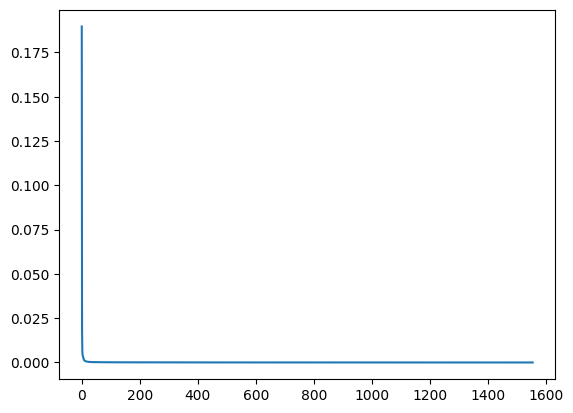

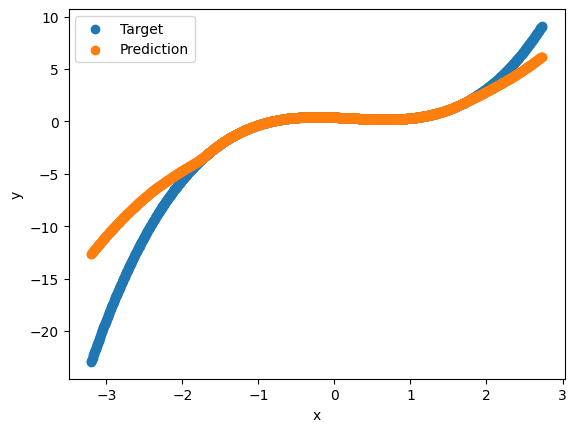

In [1]:
from src.mlp.network import Network
from src.mlp.layers import *
from src.mlp.losses import *
from src.mlp.activations import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

per = Network(
    [
        Dense(3, 32),
        LeakyReLU(),
        Dense(32, 16),
        LeakyReLU(),
        Dense(16, 1),
    ]
)

df = pd.read_csv("/home/SOS/Downloads/projekt1/regression/data.cube.train.10000.csv")

lower = df.iloc[:, 0].min()
upper = df.iloc[:, 0].max()

for i in (2, 3):
    df.insert(i - 1, f"x{i}", df["x"] ** i)
    
X = df.iloc[:, :-1].to_numpy(dtype=np.float64)
y = df.iloc[:, -1:].to_numpy(dtype=np.float64)

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)

y_mean = np.mean(y, axis=0)
y_std = np.std(y, axis=0)

print((X_mean, X_std, y_mean, y_std))

X = (X - X_mean) / X_std
y = (y - y_mean) / y_std

    
n = 50
max_epochs = 10_000
lr = 0.01

patience = 100
min_delta = 1e-6

loss_history = []
best_loss = float("inf")
epochs_without_improvement = 0

# list_df = [df[i:i + n] for i in range(0, df.shape[0], n)]

for epoch in range(max_epochs):
    epoch_loss = 0.0
    # print(f"Epoch {epoch}")
    
    indices = np.random.permutation(len(X))
    X_shuffled = X[indices]
    y_shuffled = y[indices]
    
    for start in range(0, len(X), n):
        X_batch = X_shuffled[start:start + n]
        y_batch = y_shuffled[start:start + n]
        
        pred = per.forward(X_batch)
        loss = MSE.forward(y_batch, pred)

        gradient = MSE.backward(y_batch, pred)
        per.backward(gradient)
        
        per.update(lr)
        
        epoch_loss += loss * len(X_batch)
    
    epoch_loss = epoch_loss / len(X)
    
    loss_history.append(epoch_loss)
    
    if epoch_loss < best_loss - min_delta:
        best_loss = epoch_loss
        epochs_without_improvement = 0
        # TODO save model
    else:
        epochs_without_improvement += 1
    
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: loss = {epoch_loss:.6f}")
    
    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

plt.plot(loss_history)
plt.show()


df = pd.read_csv("/home/SOS/Downloads/projekt1/regression/data.cube.test.1000.csv")

# df = df[
#     df.iloc[:, 0].between(lower, upper)
# ].copy()

for i in (2, 3):
    df.insert(i - 1, f"x{i}", df["x"] ** i)

X_test = df.iloc[:, :-1].to_numpy(dtype=np.float64)
y_test = df.iloc[:, -1:].to_numpy(dtype=np.float64)

X_test = (X_test - X_mean) / X_std
y_test = (y_test - y_mean) / y_std

pred = per.forward(X_test)

loss = MSE.forward(y_test, pred)

plt.scatter(X_test[:, 0], y_test, label = "Target")
plt.scatter(X_test[:, 0], pred, label = "Prediction")

# plt.xlim(-3, 3)
# plt.ylim(-250, 250)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()
